3.2:DATA PREPARATION

In [136]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
# data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'



In [3]:
# !wget $data -O data-week-3.csv

In [137]:
df=pd.read_csv('data-week-3.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [138]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [139]:
# making everything uniform
df.columns= df.columns.str.lower().str.replace(' ', '_')
categorical_columns= list(df.dtypes[df.dtypes=='str'].index)


for c in categorical_columns:
    df[c]=df[c].str.lower().str.replace(' ', '_')

In [7]:
# transpose the dataframe to see the columns better
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [140]:
tc=pd.to_numeric(df.totalcharges, errors='coerce')


In [141]:
tc.isnull().sum()

np.int64(11)

In [142]:
df[tc.isnull()][['customerid','totalcharges']]

,customerid,totalcharges
488,4472-lvygi,_
753,3115-czmzd,_
936,5709-lvoeq,_
1082,4367-nuyao,_
1340,1371-dwpaz,_
3331,7644-omvmy,_
3826,3213-vvolg,_
4380,2520-sgtta,_
5218,2923-arzlg,_
6670,4075-wkniu,_


In [143]:
# These are customers who just joined - their tenure is small and they haven't been billed yet, so their total charges are not available.
#  For them we simply fill the missing values with zero:

df.totalcharges= pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges= df.totalcharges.fillna(0)
df.totalcharges

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: totalcharges, Length: 7043, dtype: float64

In [144]:
# encoding the target variable
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: str

In [145]:
(df.churn == 'yes').head()

0    False
1    False
2     True
3    False
4     True
Name: churn, dtype: bool

In [146]:
# |for classification we need numbers, hence why we are casting the churn column to int. 1 for yes and 0 for no.
df.churn=(df.churn == 'yes').astype(int)


In [147]:
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

3.3 : SETTING UP THE VALIDATION FRAMEWORK

In [148]:
# splitting the data 
from sklearn.model_selection import train_test_split

In [149]:
df_full_train,df_test= train_test_split(df,test_size=0.2,random_state=1)

In [150]:
# 20% of 80 is 25% hence using test_size as 0.25
df_train, df_val = train_test_split(df_full_train, test_size=0.25,random_state=1)

In [151]:
len(df_train),len(df_val), len(df_test)

(4225, 1409, 1409)

In [152]:
# resetting the index
df_train= df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [153]:
# ISOLATING THE TARGET
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values


In [154]:
# deleting the column from the dataframe
del df_train['churn']
del df_val['churn']
del df_test['churn']

3.4: EXPLORATORY DATA ANALYSIS(EDA)

Now we explore the training data: we check for missing values, look at the distribution of the target variable, and go through the numerical and categorical columns. 
For EDA we use the full train set - train and validation together - because we will also use it to compute feature importance later.

In [155]:
df_full_train = df_full_train.reset_index(drop=True)

In [156]:
df_full_train.isnull().sum()  

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [157]:
# checking the churn rate, how many customers churned and how many remained
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [158]:
# since the churn is a column of ones and zeroes this is a shortcut of calculating the churn rate
df_full_train.churn.mean()

np.float64(0.26996805111821087)

In [159]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [160]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [161]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

3.5: FEATURE IMPORTANCE: Churn rate and risk ratio

In [162]:
# churn rate per group
global_churn = df_full_train.churn.mean()
global_churn

np.float64(0.26996805111821087)

In [163]:
# Now we look at individual variables. Let's start with gender:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
churn_male = df_full_train[df_full_train.gender == 'male'].churn.mean()


In [164]:
global_churn - churn_female

np.float64(-0.006855983216553063)

In [165]:
global_churn - churn_male

np.float64(0.006754520462819769)

In [166]:
# Both differences are close to zero, so gender is probably not an important feature: knowing whether a customer is a man or a woman tells us almost nothing about churn.
# Now let's look at a more promising variable - whether the customer has a partner. First, how many customers are there in each group?

df_full_train.partner.value_counts()

partner
no     2932
yes    2702
Name: count, dtype: int64

In [167]:
# churn ratios
churn_partner = df_full_train[df_full_train.partner== 'yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner== 'no'].churn.mean()

In [168]:
churn_partner

np.float64(0.20503330866025166)

In [169]:
churn_no_partner

np.float64(0.3298090040927694)

In [170]:
global_churn - churn_partner

np.float64(0.06493474245795922)

In [171]:
global_churn - churn_no_partner 

np.float64(-0.05984095297455855)

In [172]:
churn_no_partner / global_churn

np.float64(1.2216593879412643)

In [173]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208




partner


...

,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730




paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


3.6 FEATURE IMPORTANCE: MUTUAL INFORMATION
measure of mutual dependence between two variables

In [174]:
from sklearn.metrics import mutual_info_score

In [175]:
mutual_info_score(df_full_train.churn,df_full_train.contract)

0.0983203874041556

In [176]:
mutual_info_score(df_full_train.churn, df_full_train.partner)

0.009967689095399745

In [177]:
mutual_info_score(df_full_train.gender,df_full_train.churn)

0.0001174846211139946

In [178]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [179]:
mi=df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)


contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

3.7  FEATURE IMPORTANCE: CORRELATION

In [180]:
df_full_train.tenure.max()

np.int64(72)

In [181]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

In [182]:
# perhaps we can look at the churn rate for customers who have been with the company  for 2 months or less:
df_full_train[df_full_train.tenure <=2].churn.mean()

np.float64(0.5953420669577875)

In [183]:
# perhaps we can look at the churn rate for customers who have been with the company for more than 2 months but less than a year:
df_full_train[(df_full_train.tenure >2) & (df_full_train.tenure <=12)].churn.mean()

np.float64(0.3994413407821229)

In [184]:
# perhaps we can look at the churn rate for customers who have been with the company for more than a year:
df_full_train[df_full_train.tenure >12].churn.mean()

# in tenure there is a decrease in churn rate hence a negative correlation between tenure and churn.

np.float64(0.17634908339788277)

In [185]:
# monthly charges for less than 20 dollars
df_full_train[df_full_train.monthlycharges <20].churn.mean()

np.float64(0.08829568788501027)

In [186]:
# monthly charges for more than 20 dollars and less than 50 dollars
df_full_train[(df_full_train.monthlycharges >20) & (df_full_train.monthlycharges <=50)].churn.mean()

np.float64(0.18340943683409436)

In [187]:
# montly charges for more than 50 dollars churn rate
df_full_train[df_full_train.monthlycharges >50].churn.mean()

# in monthly charges there is an increase in churn rate hence a positive  correalation between monthly charges and churn.

np.float64(0.32499341585462205)

3.8 : ONE-HOT ENCODING

In [188]:
from sklearn.feature_extraction import DictVectorizer

In [189]:
df_train[['gender','contract','tenure']].iloc[:10]

,gender,contract,tenure
0,female,two_year,72
1,male,month-to-month,10
2,female,month-to-month,5
3,female,month-to-month,5
4,female,two_year,18
5,male,month-to-month,4
6,male,month-to-month,1
7,female,month-to-month,1
8,female,two_year,72
9,female,month-to-month,6


In [190]:

train_dicts= df_train[ categorical + numerical].to_dict(orient='records')

In [191]:
dv= DictVectorizer(sparse=False)

In [192]:
X_train= dv.fit_transform(train_dicts)

In [193]:
val_dicts= df_val[categorical + numerical].to_dict(orient='records')

In [194]:
X_val= dv.transform(val_dicts)

3.9: LOGISTIC REGRESSION
1)binary regression
2)linear vs logistic regression

In [195]:
# where z is the input to the sigmoid function
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [196]:
z= np.linspace(-7,7,51)
z

array([-7.0000000e+00, -6.7200000e+00, -6.4400000e+00, -6.1600000e+00,
       -5.8800000e+00, -5.6000000e+00, -5.3200000e+00, -5.0400000e+00,
       -4.7600000e+00, -4.4800000e+00, -4.2000000e+00, -3.9200000e+00,
       -3.6400000e+00, -3.3600000e+00, -3.0800000e+00, -2.8000000e+00,
       -2.5200000e+00, -2.2400000e+00, -1.9600000e+00, -1.6800000e+00,
       -1.4000000e+00, -1.1200000e+00, -8.4000000e-01, -5.6000000e-01,
       -2.8000000e-01,  8.8817842e-16,  2.8000000e-01,  5.6000000e-01,
        8.4000000e-01,  1.1200000e+00,  1.4000000e+00,  1.6800000e+00,
        1.9600000e+00,  2.2400000e+00,  2.5200000e+00,  2.8000000e+00,
        3.0800000e+00,  3.3600000e+00,  3.6400000e+00,  3.9200000e+00,
        4.2000000e+00,  4.4800000e+00,  4.7600000e+00,  5.0400000e+00,
        5.3200000e+00,  5.6000000e+00,  5.8800000e+00,  6.1600000e+00,
        6.4400000e+00,  6.7200000e+00,  7.0000000e+00])

In [197]:
# sigmoid function applied to z we get numbers that are  0 and 1.
sigmoid(z)

array([9.11051194e-04, 1.20508423e-03, 1.59386223e-03, 2.10780106e-03,
       2.78699622e-03, 3.68423990e-03, 4.86893124e-03, 6.43210847e-03,
       8.49286285e-03, 1.12064063e-02, 1.47740317e-02, 1.94550846e-02,
       2.55807883e-02, 3.35692233e-02, 4.39398154e-02, 5.73241759e-02,
       7.44679452e-02, 9.62155417e-02, 1.23467048e-01, 1.57095469e-01,
       1.97816111e-01, 2.46011284e-01, 3.01534784e-01, 3.63547460e-01,
       4.30453776e-01, 5.00000000e-01, 5.69546224e-01, 6.36452540e-01,
       6.98465216e-01, 7.53988716e-01, 8.02183889e-01, 8.42904531e-01,
       8.76532952e-01, 9.03784458e-01, 9.25532055e-01, 9.42675824e-01,
       9.56060185e-01, 9.66430777e-01, 9.74419212e-01, 9.80544915e-01,
       9.85225968e-01, 9.88793594e-01, 9.91507137e-01, 9.93567892e-01,
       9.95131069e-01, 9.96315760e-01, 9.97213004e-01, 9.97892199e-01,
       9.98406138e-01, 9.98794916e-01, 9.99088949e-01])

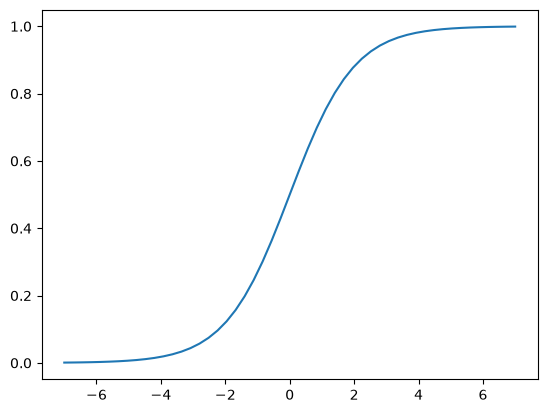

In [198]:

plt.plot(z, sigmoid(z))

In [199]:
# for linear regression.
def linear_regression(xi):
    result=w0

    for j in range(len(w)):
        result += w[j] * xi[j]

    return result

In [200]:
# for logistic regression: pass the score through the sigmoid before returning it.
def logistic_regression(xi):
    score= w0
    for j in range(len(w)):
        score += w[j] * xi[j]
    result= sigmoid(score)
    return result

3.10: TRAINING LOGISTIC REGRESSION WITH SCIKIT- LEARN


In [201]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs',max_iter=5000)
# solver='lbfgs' is the default solver in newer version of sklearn
# for older versions, you need to specify it explicitly
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [202]:
model.coef_[0].round(3)

array([ 0.683,  0.032, -0.679,  0.054, -0.018,  0.112, -0.159,  0.083,
        0.037, -0.001, -0.494,  0.689, -0.159, -0.017, -0.189,  0.069,
        0.156,  0.115, -0.159,  0.08 ,  0.282, -0.159, -0.088, -0.164,
        0.2  , -0.046,  0.082, -0.054, -0.003,  0.105, -0.013,  0.069,
       -0.033,  0.194, -0.095, -0.159,  0.289, -0.055, -0.159,  0.25 ,
        0.232, -0.159, -0.037, -0.068,  0.   ])

In [203]:
model.intercept_[0]

np.float64(-0.046900430449174614)

In [204]:
y_pred = model.predict_proba(X_val)[:,1]

In [205]:
churn_decision = y_pred >= 0.5

In [206]:
# customers that are likely to churn, we could send them a special offer to try to retain them.
df_val[churn_decision].customerid

3       8433-wxgna
8       3440-jpscl
12      7228-omtpn
19      6711-fldfb
24      2612-ranwt
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 315, dtype: str

In [207]:
y_val

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [208]:
churn_decision.astype(int)

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [209]:
# around 80% match
(y_val==churn_decision).mean()

np.float64(0.8034066713981547)

In [210]:
df_pred=pd.DataFrame()
df_pred['probabilty']=y_pred
df_pred['prediction']=churn_decision.astype(int)
df_pred['actual']=y_val

In [211]:
df_pred

,probabilty,prediction,actual
0,0.006688,0,0
1,0.204523,0,0
2,0.217560,0,0
3,0.564322,1,1
4,0.218489,0,0
...,...,...,...
1404,0.291854,0,0
1405,0.041196,0,1
1406,0.151901,0,0
1407,0.788432,1,1


In [212]:
# let see how many are correct
df_pred['correct'] = df_pred.prediction == df_pred.actual   

In [213]:
df_pred

,probabilty,prediction,actual,correct
0,0.006688,0,0,True
1,0.204523,0,0,True
2,0.217560,0,0,True
3,0.564322,1,1,True
4,0.218489,0,0,True
...,...,...,...,...
1404,0.291854,0,0,True
1405,0.041196,0,1,False
1406,0.151901,0,0,True
1407,0.788432,1,1,True


In [214]:
df_pred.correct.mean()

np.float64(0.8034066713981547)

3.11: MODEL INTERPRETATION

In [215]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=month-to-month': np.float64(0.683),
 'contract=one_year': np.float64(0.032),
 'contract=two_year': np.float64(-0.679),
 'dependents=no': np.float64(0.054),
 'dependents=yes': np.float64(-0.018),
 'deviceprotection=no': np.float64(0.112),
 'deviceprotection=no_internet_service': np.float64(-0.159),
 'deviceprotection=yes': np.float64(0.083),
 'gender=female': np.float64(0.037),
 'gender=male': np.float64(-0.001),
 'internetservice=dsl': np.float64(-0.494),
 'internetservice=fiber_optic': np.float64(0.689),
 'internetservice=no': np.float64(-0.159),
 'monthlycharges': np.float64(-0.017),
 'multiplelines=no': np.float64(-0.189),
 'multiplelines=no_phone_service': np.float64(0.069),
 'multiplelines=yes': np.float64(0.156),
 'onlinebackup=no': np.float64(0.115),
 'onlinebackup=no_internet_service': np.float64(-0.159),
 'onlinebackup=yes': np.float64(0.08),
 'onlinesecurity=no': np.float64(0.282),
 'onlinesecurity=no_internet_service': np.float64(-0.159),
 'onlinesecurity=yes': np

In [216]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=month-to-month': np.float64(0.683),
 'contract=one_year': np.float64(0.032),
 'contract=two_year': np.float64(-0.679),
 'dependents=no': np.float64(0.054),
 'dependents=yes': np.float64(-0.018),
 'deviceprotection=no': np.float64(0.112),
 'deviceprotection=no_internet_service': np.float64(-0.159),
 'deviceprotection=yes': np.float64(0.083),
 'gender=female': np.float64(0.037),
 'gender=male': np.float64(-0.001),
 'internetservice=dsl': np.float64(-0.494),
 'internetservice=fiber_optic': np.float64(0.689),
 'internetservice=no': np.float64(-0.159),
 'monthlycharges': np.float64(-0.017),
 'multiplelines=no': np.float64(-0.189),
 'multiplelines=no_phone_service': np.float64(0.069),
 'multiplelines=yes': np.float64(0.156),
 'onlinebackup=no': np.float64(0.115),
 'onlinebackup=no_internet_service': np.float64(-0.159),
 'onlinebackup=yes': np.float64(0.08),
 'onlinesecurity=no': np.float64(0.282),
 'onlinesecurity=no_internet_service': np.float64(-0.159),
 'onlinesecurity=yes': np

In [217]:
small=['contract','tenure','monthlycharges']

In [218]:
# taking a subset of the dataset
df_train[small].iloc[:10].to_dict(orient='records')

[{'contract': 'two_year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 75.55},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 80.85},
 {'contract': 'two_year', 'tenure': 18, 'monthlycharges': 20.1},
 {'contract': 'month-to-month', 'tenure': 4, 'monthlycharges': 30.5},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 75.1},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 70.3},
 {'contract': 'two_year', 'tenure': 72, 'monthlycharges': 19.75},
 {'contract': 'month-to-month', 'tenure': 6, 'monthlycharges': 109.9}]

In [219]:
dicts_train_small= df_train[small].to_dict(orient='records')
dicts_val_small= df_val[small].to_dict(orient='records')    

In [220]:
dv_small= DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [221]:
dv_small.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'monthlycharges', 'tenure'], dtype=object)

In [222]:
X_train_small= dv_small.transform(dicts_train_small)

In [223]:
model_small = LogisticRegression(solver='lbfgs',max_iter=1000)
model_small.fit(X_train_small, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [224]:
w0=model_small.intercept_[0]
w0

np.float64(-2.4779575953986557)

In [225]:
w = model_small.coef_[0]
w.round(3)

array([ 0.971, -0.024, -0.948,  0.027, -0.036])

In [226]:
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

In [227]:
-2.47 + 0.97 + 50* 0.027 + 5* (-0.036)

-0.3300000000000001

In [228]:
# _ means take the previous  output  and use it as an input to the next function.

sigmoid(_)

np.float64(0.41824062315816374)

3:12 : USING THE MODEL

In [230]:
dicts_df_full_train = df_full_train[categorical + numerical] . to_dict(orient='records')

In [231]:
dv= DictVectorizer(sparse=False)

In [232]:
X_full_train = dv.fit_transform(dicts_df_full_train)

In [233]:
y_full_train = df_full_train.churn.values

In [235]:
model= LogisticRegression(solver='lbfgs',max_iter=5000)
model.fit(X_full_train, y_full_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [236]:
dicts_test = df_test[categorical + numerical] . to_dict(orient='records')

In [237]:
X_test = dv.transform(dicts_test)

In [238]:
y_pred = model.predict_proba(X_test)[:, 1]

In [239]:
churn_decision = (y_pred >= 0.5)

In [240]:
(churn_decision == y_test).mean()

np.float64(0.8126330731014905)

In [241]:
# scoring one customer
customer = dicts_test[-1]
customer

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'yes',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'yes',
 'onlinebackup': 'no',
 'deviceprotection': 'yes',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check',
 'tenure': 17,
 'monthlycharges': 104.2,
 'totalcharges': 1743.5}

In [242]:
X_small= dv. transform([customer])

In [243]:
model.predict_proba(X_small)[0, 1]

np.float64(0.6400139478690677)

In [244]:
y_test[-1]

np.int64(1)